# A/B testing

Hypothesis: moving the gate from 30 to 40 changes 7-day retention.
Primary metric: **retention_7**. This is the most business-relevant metric because it measures whether players remain engaged over the full 7-day window.

Secondary metric: **retention_1**.

Guardrail / engagement metric: **sum_gamerounds**. More gamerounds typically indicate more ad and purchase exposure, so this helps check for unintended side effects.

- Significance level: **α = 0.05**
- Power: **0.8**
- Test type: **two-sided**


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from statsmodels.stats.proportion import (
    proportions_ztest, confint_proportions_2indep, proportion_effectsize)
from statsmodels.stats.power import NormalIndPower




In [2]:
df=pd.read_csv('cookie_cats.csv')
df

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True
...,...,...,...,...,...
90184,9999441,gate_40,97,True,False
90185,9999479,gate_40,30,False,False
90186,9999710,gate_30,28,True,False
90187,9999768,gate_40,51,True,False


In [3]:
df.describe()

,userid,sum_gamerounds
count,9.018900e+04,90189.000000
mean,4.998412e+06,51.872457
std,2.883286e+06,195.050858
min,1.160000e+02,0.000000
25%,2.512230e+06,5.000000
50%,4.995815e+06,16.000000
75%,7.496452e+06,51.000000
max,9.999861e+06,49854.000000


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 90189 entries, 0 to 90188
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   userid          90189 non-null  int64
 1   version         90189 non-null  str  
 2   sum_gamerounds  90189 non-null  int64
 3   retention_1     90189 non-null  bool 
 4   retention_7     90189 non-null  bool 
dtypes: bool(2), int64(2), str(1)
memory usage: 2.8 MB


In [5]:
df.isnull().sum()

userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

**since there is no null values and no duplicates in the dataset, we can proceed with the analysis.**

In [7]:
counts = df["version"].value_counts().sort_index()
chi2, p_srm = stats.chisquare(counts, f_exp=[len(df) / 2] * 2)
print(counts.to_dict(), f"SRM p-value = {p_srm:.4f}")

{'gate_30': 44700, 'gate_40': 45489} SRM p-value = 0.0086


"To ensure our randomization logic didn't fail, we conducted a Chi-Square Goodness-of-Fit test as an SRM guardrail check. Using a strict industry-standard significance threshold of \(\alpha = 0.001\), our test yielded a p-value of 0.0086. Because our p-value is greater than our alpha (\(0.0086 > 0.001\)), we fail to reject the null hypothesis of a fair split and conclude that no severe sample ratio mismatch occurred. It is safe to proceed with the primary A/B analysis."

###  Clean and explore

In [8]:
print(df['sum_gamerounds'].describe())

count    90189.000000
mean        51.872457
std        195.050858
min          0.000000
25%          5.000000
50%         16.000000
75%         51.000000
max      49854.000000
Name: sum_gamerounds, dtype: float64


In [9]:
(df['sum_gamerounds']== 0).sum()

np.int64(3994)

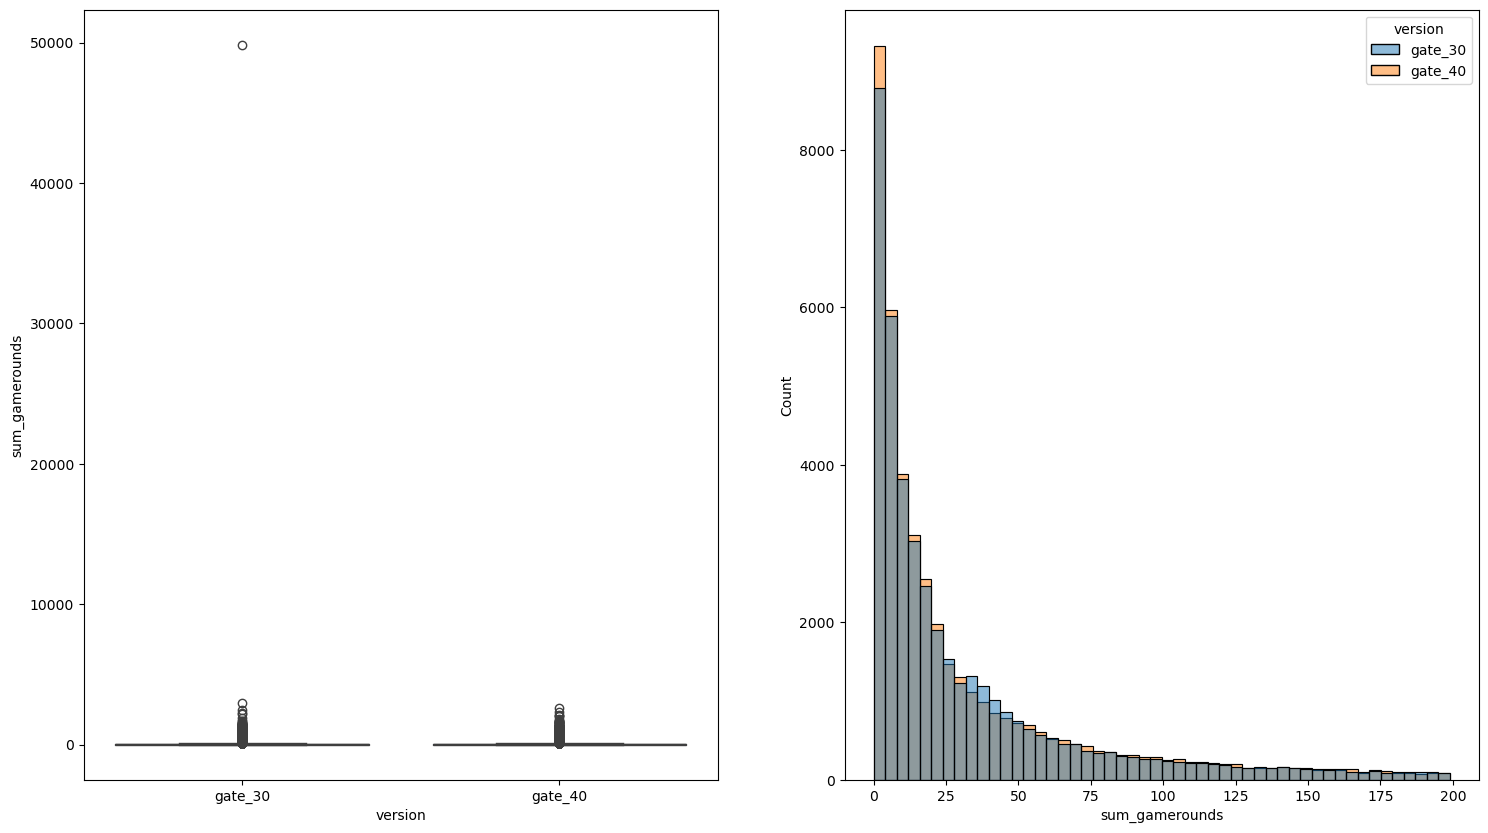

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(18, 10))
sns.boxplot(data=df, x="version", y="sum_gamerounds", ax=ax[0])
sns.histplot(df[df.sum_gamerounds < 200], x="sum_gamerounds", hue="version",
             bins=50, ax=ax[1])
plt.show()

In [11]:
#99%percentile of sum_gamerounds
df['sum_gamerounds'].quantile(0.99)

np.float64(493.0)

**50000 in gate_30 is unlogical number, so we will remove it from the dataset so we will use the 99.99% percentile to remove the outliers from the dataset.**

In [12]:
df=df[df['sum_gamerounds'] < 40000]

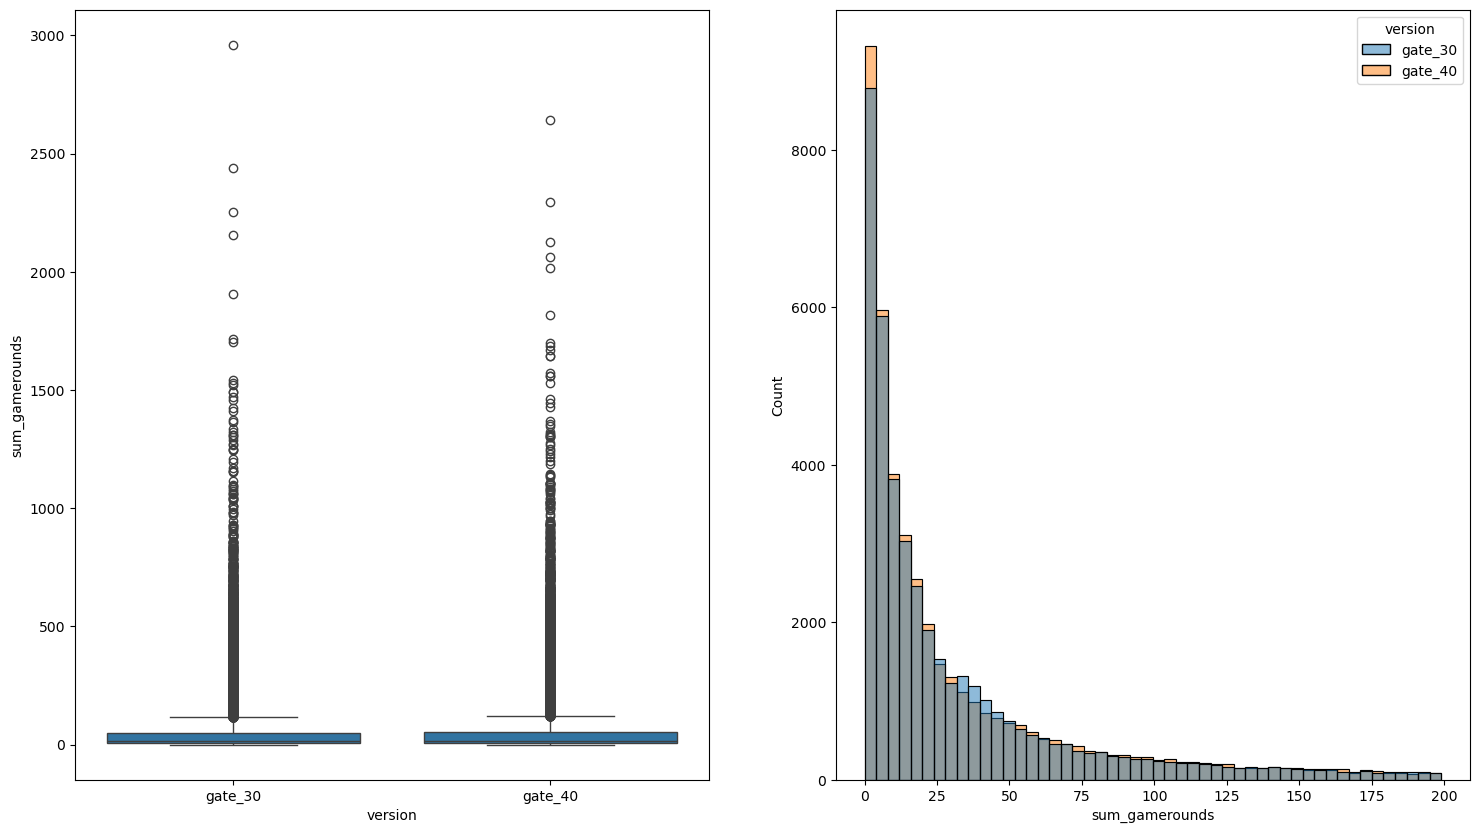

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(18, 10))
sns.boxplot(data=df, x="version", y="sum_gamerounds", ax=ax[0])
sns.histplot(df[df.sum_gamerounds < 200], x="sum_gamerounds", hue="version",
             bins=50, ax=ax[1])
plt.show()

In [14]:
df['sum_gamerounds'].quantile(0.99)

np.float64(493.0)

In [15]:
df[df['sum_gamerounds']==0].count()

userid            3994
version           3994
sum_gamerounds    3994
retention_1       3994
retention_7       3994
dtype: int64

**If we deleted those zero-round players, we would be ignoring people who installed the game and immediately uninstalled or gave up. Including them ensures our sample reflects all real-world installs .**

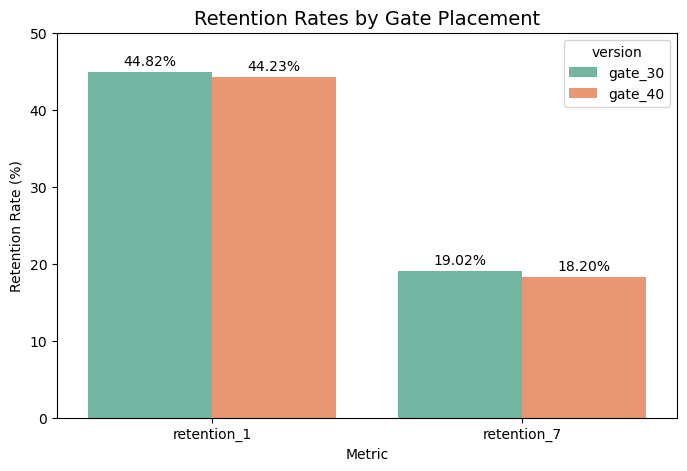

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate true retention rates per version
retention_summary = df.groupby("version")[["retention_1", "retention_7"]].mean().reset_index()

# Melt data into long format for easy plotting with seaborn
df_plot = retention_summary.melt(id_vars="version", var_name="Retention_Metric", value_name="Retention_Rate")

# Convert rates to percentages for display
df_plot["Retention_Percentage"] = df_plot["Retention_Rate"] * 100

# Plot grouped bar chart
plt.figure(figsize=(8, 5))
ax = sns.barplot(data=df_plot, x="Retention_Metric", y="Retention_Percentage", hue="version", palette="Set2")

plt.title("Retention Rates by Gate Placement", fontsize=14)
plt.ylabel("Retention Rate (%)")
plt.xlabel("Metric")
plt.ylim(0, 50)

# Add value labels on top of each bar
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f"{p.get_height():.2f}%", 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha='center', va='bottom', fontsize=10, xytext=(0, 3), 
                    textcoords='offset points')

plt.show()


In [17]:
def compare_retention(metric):
    g = df.groupby("version")[metric].agg(x="sum", n="count")
    x, n = g["x"].astype(int).values, g["n"].values   # [gate_30, gate_40]
    rates = x / n

    z, p = proportions_ztest(x, n)                    # pooled SE (tests H0)
    low, high = confint_proportions_2indep(           # unpooled SE (CI)
        x[1], n[1], x[0], n[0], compare="diff", method="wald")

    return {"metric": metric,
            "gate_30": rates[0], "gate_40": rates[1],
            "diff (40-30)": rates[1] - rates[0],
            "CI_low": low, "CI_high": high,
            "z": z, "p_value": p}

results = pd.DataFrame([compare_retention(m) for m in ["retention_1", "retention_7"]])
print(results.round(4))

        metric  gate_30  gate_40  diff (40-30)  CI_low  CI_high       z  \
0  retention_1   0.4482   0.4423       -0.0059 -0.0124   0.0006  1.7871   
1  retention_7   0.1902   0.1820       -0.0082 -0.0133  -0.0031  3.1574   

   p_value  
0   0.0739  
1   0.0016  


Day 1: Inconclusive/No significant change ($p = 0.0739$). Moving the gate does not impact whether players return the next day.Day 7: Clear negative impact ($p = 0.0016$). Keeping the gate at level 30 yields higher long-term retention.Conclusion: Because 7-day retention is our primary metric, the overall test shows that moving the gate to level 40 hurts player retention over time.

In [18]:

# Set random seed for reproducibility
rng = np.random.default_rng(42)

# Extract binary arrays (1 for retained, 0 for not retained)
a = df.loc[df.version == "gate_30", "retention_7"].astype(int).values
b = df.loc[df.version == "gate_40", "retention_7"].astype(int).values

# Run 5,000 bootstrap iterations
iterations = 5000
diffs = [
    rng.choice(b, len(b)).mean() - rng.choice(a, len(a)).mean()
    for _ in range(iterations)
]

# Calculate 95% Confidence Interval
ci_low, ci_high = np.percentile(diffs, [2.5, 97.5])
prob_gate40_better = np.mean(np.array(diffs) > 0)

print(f"Bootstrap 95% CI for difference (gate_40 - gate_30): [{ci_low:.4f}, {ci_high:.4f}]")
print(f"Probability that gate_40 is better than gate_30: {prob_gate40_better:.4f}")

Bootstrap 95% CI for difference (gate_40 - gate_30): [-0.0133, -0.0033]
Probability that gate_40 is better than gate_30: 0.0010


**Using two completely different statistical methods—a parametric Z-test and a non-parametric Bootstrap simulation—gives us identical results**